In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv('dataset_mansion.csv',index_col=0)
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 56231 entries, 0 to 56230
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   MTime                                56231 non-null  object 
 1   Consumption                          56231 non-null  object 
 2   Latitude                             56040 non-null  float64
 3   Longitude                            56040 non-null  float64
 4   Place                                56040 non-null  object 
 5   AirTemperature(degC)                 56023 non-null  float64
 6   HighestTemperature(degC)             56028 non-null  float64
 7   LowestTemperature(degC)              56028 non-null  float64
 8   RelativeHumidity(%)                  55942 non-null  float64
 9   WindSpeed(m/s)                       55613 non-null  float64
 10  MaximumWindSpeed(m/s)                55490 non-null  float64
 11  MinimumWindSpeed(m/s)            

In [25]:
# Fix column types that pandas misread, so the rest of the exploration is accurate:
# - 'Consumption' uses a comma as decimal separator -> loaded as text, needs to become float
# - 'MTime' is a timestamp string -> parse to datetime so we can explore the time range
df['Consumption'] = df['Consumption'].str.replace(',', '.', regex=False).astype(float)
df['MTime'] = pd.to_datetime(df['MTime'])

print(df[['MTime', 'Consumption']].dtypes)

df.drop(columns=["Latitude", "Longitude", "Place", "PresentWeather(rank)"], inplace=True)

MTime          datetime64[ns]
Consumption           float64
dtype: object


In [14]:
print(df.isnull().sum()) # check for missing values

MTime                                    0
Consumption                              0
AirTemperature(degC)                   208
HighestTemperature(degC)               203
LowestTemperature(degC)                203
RelativeHumidity(%)                    289
WindSpeed(m/s)                         618
MaximumWindSpeed(m/s)                  741
MinimumWindSpeed(m/s)                  741
WindDirection(deg)                     501
PrecipitationAmount(mm)                303
MaximumPrecipitationIntensity(mm/h)    321
AirPressure(hPa)                       210
dtype: int64


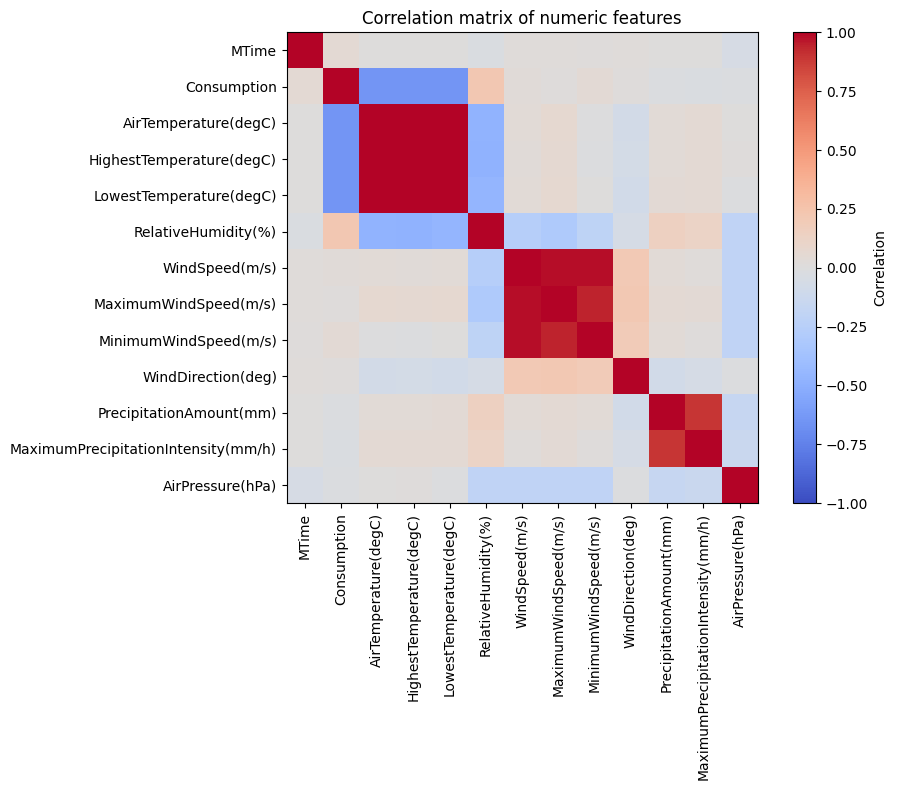

Consumption                            1.000000
RelativeHumidity(%)                    0.225464
MTime                                  0.052036
MinimumWindSpeed(m/s)                  0.046505
WindSpeed(m/s)                         0.028468
MaximumWindSpeed(m/s)                  0.013435
WindDirection(deg)                     0.010414
PrecipitationAmount(mm)               -0.017845
AirPressure(hPa)                      -0.019753
MaximumPrecipitationIntensity(mm/h)   -0.029924
LowestTemperature(degC)               -0.642765
AirTemperature(degC)                  -0.645008
HighestTemperature(degC)              -0.645574
Name: Consumption, dtype: float64


In [16]:
# Correlation between numeric features (helps spot which weather variables
# relate to Consumption and which weather columns duplicate each other)

corr = df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation matrix of numeric features')
plt.tight_layout()
plt.show()

print(corr['Consumption'].sort_values(ascending=False))